# Robustness of the Linear and Ridge Results

Two checks on whether the cross-validation conclusions depend on how the development data were split.

1. **Repeated cross-validation (data-partition variability).** Linear and ridge regression are deterministic, so the only source of variation is which buildings land in which fold. The 5-fold experiment is repeated with 5 different shuffle seeds, giving 25 validation scores per configuration.
2. **Design-grouped cross-validation (near-duplicate leakage).** Each building design appears at up to four orientations with nearly identical loads. Random folds can place copies of one design in both training and validation. Grouped folds keep every copy of a design in the same fold.

Every configuration from notebook 02 is included: linear regression with mutual-information (MI) and forward selection, and tuned ridge with MI, at 2, 4, 6, and 8 features. The per-fold procedure lives in `src/experiments.py` and reproduces notebook 02 exactly.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import (
    FEATURE_COLUMNS,
    FEATURE_COUNTS,
    REPEAT_CV_SEEDS,
    TARGET_COLUMNS,
)
from src.data import create_dev_test_split, load_data, make_design_groups
from src.evaluation import get_cv, get_group_cv
from src.experiments import evaluate_linear, evaluate_ridge

pd.set_option("display.max_colwidth", None)

TABLES = project_root / "results" / "tables"
FIGURES = project_root / "results" / "figures"

## Development data and design groups

A design is every feature except orientation. Most designs in the development set have 3 or 4 orientation copies; the rest went to the held-out test set.

In [2]:
df = load_data()
X_dev, X_test, y_dev, y_test = create_dev_test_split(df)

groups = make_design_groups(X_dev)

print("Development rows:", len(X_dev))
print("Distinct designs:", groups.nunique())
print("\nCopies per design (count of designs):")
print(groups.value_counts().value_counts().sort_index())

Development rows: 614
Distinct designs: 190

Copies per design (count of designs):
count
1     4
2    26
3    82
4    78
Name: count, dtype: int64


### Check: grouped folds never split a design

In [3]:
for seed in REPEAT_CV_SEEDS:
    for train_idx, val_idx in get_group_cv(seed).split(X_dev, groups=groups):
        shared = set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])
        assert not shared, f"seed {seed}: designs in both train and validation"

print("All grouped folds keep each design on one side of the split.")

All grouped folds keep each design on one side of the split.


### Check: shared functions reproduce notebook 02

Linear regression with MI selection on the original seed-42 folds should match the saved notebook 02 results exactly.

In [4]:
check_rows = []

for target in TARGET_COLUMNS:
    for k in FEATURE_COUNTS:
        for fold, (train_idx, val_idx) in enumerate(get_cv().split(X_dev), start=1):
            row = evaluate_linear(
                X_dev.iloc[train_idx], y_dev[target].iloc[train_idx],
                X_dev.iloc[val_idx], y_dev[target].iloc[val_idx],
                k,
            )
            check_rows.append({"target": target, "fold": fold, **row})

check = pd.DataFrame(check_rows).set_index(["target", "n_features", "fold"]).sort_index()
saved = (
    pd.read_csv(TABLES / "linear_feature_ablation_cv.csv")
    .set_index(["target", "n_features", "fold"])
    .sort_index()
)

print("Largest RMSE difference:", float((check["rmse"] - saved["rmse"]).abs().max()))

Largest RMSE difference: 0.0


## Experiment runner

For one cross-validation scheme, run every configuration on every fold of every seed. `scheme="random"` uses shuffled K-fold; `scheme="grouped"` uses design-grouped K-fold. Ridge tunes alpha with an inner 3-fold search on each training fold, exactly as in notebook 02.

In [5]:
CONFIGS = (
    [("linear", "mi", k) for k in FEATURE_COUNTS]
    + [("linear", "forward", k) for k in FEATURE_COUNTS if k < len(FEATURE_COLUMNS)]
    + [("ridge_tuned", "mi", k) for k in FEATURE_COUNTS]
)


def run_cv_experiment(scheme, seeds):
    rows = []

    for seed in seeds:
        if scheme == "random":
            splits = list(get_cv(seed).split(X_dev))
        elif scheme == "grouped":
            splits = list(get_group_cv(seed).split(X_dev, groups=groups))
        else:
            raise ValueError(scheme)

        for target in TARGET_COLUMNS:
            for fold, (train_idx, val_idx) in enumerate(splits, start=1):
                data = (
                    X_dev.iloc[train_idx], y_dev[target].iloc[train_idx],
                    X_dev.iloc[val_idx], y_dev[target].iloc[val_idx],
                )

                for model, selector, k in CONFIGS:
                    if model == "linear":
                        row = evaluate_linear(*data, k, method=selector)
                    else:
                        row = evaluate_ridge(*data, k)

                    rows.append({
                        "cv_scheme": scheme,
                        "cv_seed": seed,
                        "target": target,
                        "fold": fold,
                        **row,
                    })

        print(f"{scheme}: seed {seed} done")

    return pd.DataFrame(rows)

## Part A: repeated random cross-validation

5 shuffle seeds × 5 folds = 25 validation scores per configuration.

In [6]:
random_df = run_cv_experiment("random", REPEAT_CV_SEEDS)
random_df.to_csv(TABLES / "linear_ridge_repeated_cv.csv", index=False)

print("Rows:", len(random_df))

random: seed 0 done


random: seed 1 done


random: seed 2 done


random: seed 3 done


random: seed 4 done
Rows: 550


## Part B: design-grouped cross-validation

The same 5 seeds and configurations, with each design's orientation copies kept in one fold.

In [7]:
grouped_df = run_cv_experiment("grouped", REPEAT_CV_SEEDS)
grouped_df.to_csv(TABLES / "linear_ridge_grouped_cv.csv", index=False)

print("Rows:", len(grouped_df))

grouped: seed 0 done


grouped: seed 1 done


grouped: seed 2 done


grouped: seed 3 done


grouped: seed 4 done
Rows: 550


## Random versus grouped folds

Mean ± standard deviation of validation RMSE over all 25 folds. `grouped_change_pct` is how much higher the grouped RMSE is than the random-fold RMSE.

In [8]:
robust_df = pd.concat([random_df, grouped_df], ignore_index=True)

KEYS = ["target", "model", "selector", "n_features"]

rmse_summary = (
    robust_df
    .groupby(["cv_scheme"] + KEYS)["rmse"]
    .agg(["mean", "std"])
    .unstack("cv_scheme")
)
rmse_summary.columns = [f"{scheme}_{stat}" for stat, scheme in rmse_summary.columns]
rmse_summary = rmse_summary[["random_mean", "random_std", "grouped_mean", "grouped_std"]]
rmse_summary["grouped_change_pct"] = 100 * (
    rmse_summary["grouped_mean"] / rmse_summary["random_mean"] - 1
)

rmse_summary.round(3)

random_mean  random_std  \
target       model       selector n_features                            
cooling_load linear      forward  2                 3.744       0.301   
                                  4                 3.254       0.290   
                                  6                 3.231       0.288   
                         mi       2                 6.522       0.394   
                                  4                 3.978       0.390   
                                  6                 3.228       0.288   
                                  8                 3.239       0.288   
             ridge_tuned mi       2                 6.522       0.393   
                                  4                 3.979       0.391   
                                  6                 3.227       0.289   
                                  8                 3.238       0.289   
heating_load linear      forward  2                 3.704       0.234   
                                  4                 3.000       0.217   
                                  6                 2.937       0.211   
                         mi       2                 7.134       0.377   
                                  4                 4.224       0.363   
                                  6                 2.942       0.215   
                                  8                 2.934       0.210   
             ridge_tuned mi       2                 7.134       0.377   
                                  4                 4.224       0.363   
                                  6                 2.942       0.216   
                                  8                 2.935       0.211   

                                              grouped_mean  grouped_std  \
target       model       selector n_features                              
cooling_load linear      forward  2                  3.833        0.500   
                                  4                  3.304        0.484   
                                  6                  3.282        0.471   
                         mi       2                  6.591        0.350   
                                  4                  4.040        0.376   
                                  6                  3.277        0.468   
                                  8                  3.294        0.472   
             ridge_tuned mi       2                  6.591        0.352   
                                  4                  4.040        0.378   
                                  6                  3.279        0.470   
                                  8                  3.298        0.476   
heating_load linear      forward  2                  3.751        0.369   
                                  4                  3.101        0.406   
                                  6                  3.038        0.413   
                         mi       2                  7.219        0.408   
                                  4                  4.290        0.394   
                                  6                  3.016        0.415   
                                  8                  3.015        0.415   
             ridge_tuned mi       2                  7.219        0.410   
                                  4                  4.291        0.395   
                                  6                  3.015        0.416   
                                  8                  3.014        0.416   

                                              grouped_change_pct  
target       model       selector n_features                      
cooling_load linear      forward  2                        2.386  
                                  4                        1.557  
                                  6                        1.589  
                         mi       2                        1.064  
                                  4                        1.540  
                       

## Two kinds of variability

- **Fold-to-fold std:** spread of the 25 individual fold scores. Some folds are simply harder than others.
- **Between-repeat std:** spread of the five 5-fold averages, one per shuffle seed. This is how much the reported cross-validation estimate would move if a different seed had been chosen.

A small between-repeat std means the seed-42 results in notebook 02 are not an accident of one particular split.

In [9]:
seed_means = (
    robust_df
    .groupby(["cv_scheme"] + KEYS + ["cv_seed"])["rmse"]
    .mean()
)

variability = pd.DataFrame({
    "fold_to_fold_std": robust_df.groupby(["cv_scheme"] + KEYS)["rmse"].std(),
    "between_repeat_std": seed_means.groupby(["cv_scheme"] + KEYS).std(),
    "seed_mean_min": seed_means.groupby(["cv_scheme"] + KEYS).min(),
    "seed_mean_max": seed_means.groupby(["cv_scheme"] + KEYS).max(),
})

variability.round(3)

fold_to_fold_std  \
cv_scheme target       model       selector n_features                     
grouped   cooling_load linear      forward  2                      0.500   
                                            4                      0.484   
                                            6                      0.471   
                                   mi       2                      0.350   
                                            4                      0.376   
                                            6                      0.468   
                                            8                      0.472   
                       ridge_tuned mi       2                      0.352   
                                            4                      0.378   
                                            6                      0.470   
                                            8                      0.476   
          heating_load linear      forward  2                      0.369   
                                            4                      0.406   
                                            6                      0.413   
                                   mi       2                      0.408   
                                            4                      0.394   
                                            6                      0.415   
                                            8                      0.415   
                       ridge_tuned mi       2                      0.410   
                                            4                      0.395   
                                            6                      0.416   
                                            8                      0.416   
random    cooling_load linear      forward  2                      0.301   
                                            4                      0.290   
                                            6                      0.288   
                                   mi       2                      0.394   
                                            4                      0.390   
                                            6                      0.288   
                                            8                      0.288   
                       ridge_tuned mi       2                      0.393   
                                            4                      0.391   
                                            6                      0.289   
                                            8                      0.289   
          heating_load linear      forward  2                      0.234   
                                            4                      0.217   
                                            6                      0.211   
                                   mi       2                      0.377   
                                            4                      0.363   
                                            6                      0.215   
                                            8                      0.210   
                       ridge_tuned mi       2                      0.377   
                                            4                      0.363   
                                            6                      0.216   
                                            8                      0.211   

                                                        between_repeat_std  \
cv_scheme target       model       selector n_features                       
grouped   cooling_load linear      forward  2                        0.087   
                                            4                        0.053   
                                            6                        0.049   
                                   mi       2                        0.060   
                                            4                        0.023   
             

## Does forward selection still beat MI?

Paired comparison on identical folds: MI RMSE minus forward-selection RMSE (positive = forward selection better), across all 25 folds of each scheme.

In [10]:
linear_rows = robust_df[
    (robust_df["model"] == "linear")
    & (robust_df["n_features"] < len(FEATURE_COLUMNS))
]

paired = linear_rows.pivot_table(
    index=["cv_scheme", "target", "n_features", "cv_seed", "fold"],
    columns="selector",
    values="rmse",
)
paired["mi_minus_forward"] = paired["mi"] - paired["forward"]

paired.groupby(["cv_scheme", "target", "n_features"])["mi_minus_forward"].agg(
    mean="mean",
    std="std",
    min="min",
    folds_forward_better=lambda d: f"{int((d > 0).sum())}/{len(d)}",
).round(3)

mean    std    min folds_forward_better
cv_scheme target       n_features                                          
grouped   cooling_load 2           2.758  0.576  1.933                25/25
                       4           0.735  0.291  0.093                25/25
                       6          -0.005  0.012 -0.045                 0/25
          heating_load 2           3.468  0.559  2.442                25/25
                       4           1.189  0.389  0.372                25/25
                       6          -0.021  0.061 -0.199                 9/25
random    cooling_load 2           2.778  0.285  2.251                25/25
                       4           0.725  0.235  0.165                25/25
                       6          -0.003  0.007 -0.030                 0/25
          heating_load 2           3.430  0.342  2.825                25/25
                       4           1.224  0.271  0.759                25/25
                       6           0.005  0.029 -0.070                14/25

## Ridge versus linear across splits

Paired difference (ridge RMSE minus linear RMSE, MI selection) over the same 25 folds. Values near zero confirm that regularization does not change predictive accuracy here.

In [11]:
mi_rows = robust_df[robust_df["selector"] == "mi"]

ridge_vs_linear = mi_rows.pivot_table(
    index=["cv_scheme", "target", "n_features", "cv_seed", "fold"],
    columns="model",
    values="rmse",
)
ridge_vs_linear["ridge_minus_linear"] = (
    ridge_vs_linear["ridge_tuned"] - ridge_vs_linear["linear"]
)

ridge_vs_linear.groupby(["cv_scheme", "target", "n_features"])["ridge_minus_linear"].agg(
    ["mean", "std", "min", "max"]
).round(4)

mean     std     min     max
cv_scheme target       n_features                                
grouped   cooling_load 2          -0.0002  0.0065 -0.0147  0.0152
                       4           0.0007  0.0043 -0.0078  0.0161
                       6           0.0016  0.0099 -0.0080  0.0474
                       8           0.0033  0.0140 -0.0080  0.0514
          heating_load 2          -0.0000  0.0079 -0.0200  0.0137
                       4           0.0011  0.0044 -0.0073  0.0128
                       6          -0.0010  0.0034 -0.0113  0.0053
                       8          -0.0009  0.0036 -0.0110  0.0051
random    cooling_load 2          -0.0004  0.0047 -0.0158  0.0088
                       4           0.0004  0.0050 -0.0157  0.0065
                       6          -0.0007  0.0041 -0.0194  0.0027
                       8          -0.0011  0.0049 -0.0174  0.0027
          heating_load 2          -0.0000  0.0056 -0.0178  0.0132
                       4           0.0006  0.0040 -0.0146  0.0067
                       6           0.0008  0.0061 -0.0155  0.0203
                       8           0.0008  0.0059 -0.0166  0.0154

## Robustness figure

Linear regression RMSE (mean ± std over 25 folds) by feature count. Color shows the selection method; solid lines are random folds and dotted lines are design-grouped folds. Ridge is omitted because it matches linear regression.

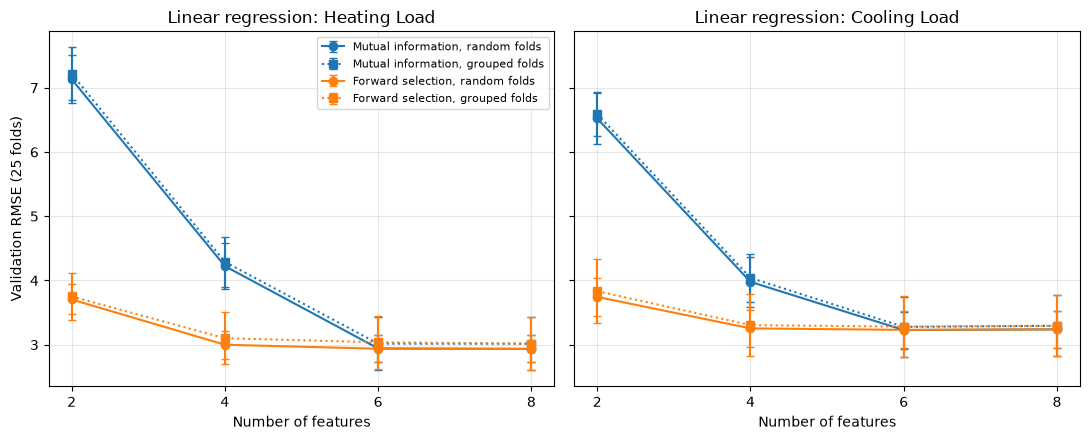

In [12]:
plot_data = (
    robust_df[robust_df["model"] == "linear"]
    .groupby(["cv_scheme", "target", "selector", "n_features"])["rmse"]
    .agg(["mean", "std"])
    .reset_index()
)

# The 8-feature model has no selection step, so it is the endpoint for both methods
full = plot_data[(plot_data["selector"] == "mi") & (plot_data["n_features"] == 8)]
plot_data = pd.concat([plot_data, full.assign(selector="forward")], ignore_index=True)

colors = {"mi": "tab:blue", "forward": "tab:orange"}
labels = {"mi": "Mutual information", "forward": "Forward selection"}
styles = {"random": "-", "grouped": ":"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, target in zip(axes, TARGET_COLUMNS):
    for selector in ["mi", "forward"]:
        for scheme in ["random", "grouped"]:
            data = plot_data[
                (plot_data["target"] == target)
                & (plot_data["selector"] == selector)
                & (plot_data["cv_scheme"] == scheme)
            ].sort_values("n_features")

            ax.errorbar(
                data["n_features"],
                data["mean"],
                yerr=data["std"],
                color=colors[selector],
                linestyle=styles[scheme],
                marker="o" if scheme == "random" else "s",
                capsize=3,
                label=f"{labels[selector]}, {scheme} folds",
            )

    ax.set_title(f"Linear regression: {target.replace('_', ' ').title()}")
    ax.set_xlabel("Number of features")
    ax.set_xticks(FEATURE_COUNTS)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Validation RMSE (25 folds)")
axes[0].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES / "linear_robustness_cv.png", dpi=200, bbox_inches="tight")
plt.show()

## Notes and limitations

- **Inner tuning folds are not grouped.** Ridge's alpha search uses ordinary shuffled inner folds, so copies of a design can be split during tuning. Because alpha has almost no effect on accuracy here, this cannot meaningfully change the results; outer validation folds are fully grouped.
- **The held-out test set shares designs with the development set.** The original 80/20 split was random, so most test rows have orientation copies in the development data. A test-set score will therefore behave like the random-fold estimates, not the grouped ones. This matters most for random forest.